# Classificação da Patologia Predominante — AASE 2026/27
**Fase 4 CRISP-DM — Modelação: Classificação**

> Prevê a patologia predominante do episódio (14 classes possíveis, 6 presentes nos dados).

| Ficheiro lido | Produzido por |
|---|---|
| `03_data_preparation/dataset_final.csv` | `data_preparation.ipynb § 7` |
| `03_data_preparation/metadata.csv` | `data_preparation.ipynb § 7` |

| Output | Descrição |
|---|---|
| `train.csv` | Conjunto de treino com features normalizadas (`_z`) |
| `test.csv` | Conjunto de teste com mesma normalização |
| `normalisation_params.csv` | Parâmetros z-score calculados no treino |

## 0. Imports e configuração

In [1]:
import csv
import math
import random
import statistics
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

C = {
    "blue":   "#2a78d6",
    "orange": "#eb6834",
    "teal":   "#1baf7a",
    "yellow": "#eda100",
    "red":    "#d03b3b",
    "grey":   "#8996ae",
    "bg":     "#f4f7fc",
    "surf":   "#ffffff",
    "text":   "#0d1219",
    "text2":  "#4a5568",
}

plt.rcParams.update({
    "figure.facecolor":  C["bg"],
    "axes.facecolor":    C["surf"],
    "axes.edgecolor":    "#dce3f0",
    "axes.labelcolor":   C["text2"],
    "axes.grid":         True,
    "axes.axisbelow":    True,
    "grid.color":        "#e6eaf3",
    "grid.linewidth":    0.8,
    "xtick.color":       C["text2"],
    "ytick.color":       C["text2"],
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "font.family":       "sans-serif",
    "font.size":         10,
    "axes.titlesize":    12,
    "axes.titleweight":  "semibold",
    "axes.titlepad":     10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "figure.dpi":        110,
})

DATA_DIR = Path("../03_data_preparation")
OUT_DIR  = Path("../03_data_preparation")   # train/test ficam em 03 para o validação aceder
SEED     = 42
random.seed(SEED)

def safe_float(v):
    try:    return float(v)
    except: return None

print("Pronto.")

Pronto.


## 1. Carregar dataset agregado

Carrega `dataset_final.csv` produzido pela Fase 3.

In [2]:
with open(DATA_DIR / "dataset_final.csv", newline="", encoding="utf-8") as f:
    features = list(csv.DictReader(f))

with open(DATA_DIR / "metadata.csv", newline="", encoding="utf-8") as f:
    meta = list(csv.DictReader(f))

# converter numérico
FEATURE_COLS = [
    "sat_o2_mean",    "sat_o2_std",    "sat_o2_min",    "sat_o2_max",
    "puls_rate_mean", "puls_rate_std", "puls_rate_min", "puls_rate_max",
    "perfusion_mean", "perfusion_std", "perfusion_min", "perfusion_max",
    "desat_count",    "desat_pct",
]
for row in features:
    for c in FEATURE_COLS + ["duracao_dias", "carga_dessaturacao", "pat_label"]:
        row[c] = safe_float(row.get(c))

pat_to_label = {r["pat_nome"]: int(r["pat_label"]) for r in meta}
label_to_pat = {int(r["pat_label"]): r["pat_nome"]  for r in meta}
pats_por_freq = [label_to_pat[i] for i in sorted(label_to_pat)]
dist_pat = Counter(r["pat_nome"] for r in meta
                   for _ in range(int(r["n_episodios"])))

features_com_pat = [r for r in features if r["pat_label"] is not None and r["pat_label"] >= 0]

print(f"Episódios carregados:         {len(features)}")
print(f"Com patologia definida:       {len(features_com_pat)}")
print(f"Features numéricas:           {len(FEATURE_COLS)}")
print(f"Classes de patologia:         {len(pat_to_label)}")
print()
for p, lbl in pat_to_label.items():
    print(f"  {lbl:2d}  {p}")

Episódios carregados:         47
Com patologia definida:       39
Features numéricas:           14
Classes de patologia:         6

   0  Doença das Membranas Hialinas
   1  Icterícia Neonatal
   2  Citomegalovírus
   3  Anemia
   4  Displasia Broncopulmonar
   5  Persistência do Canal Arterial


## 2. Divisão treino/teste — 80/20 estratificado

Estratificação por `pat_label`. Episódios sem patologia (`pat_label == -1`) são mantidos no `dataset_final.csv` mas excluídos do split.

Episódios com patologia: 39
Treino: 32  |  Teste: 7

Patologia                             Treino   Teste  % treino
--------------------------------------------------------------
  Doença das Membranas Hialinas           19       5     79.2%
  Icterícia Neonatal                       6       1     85.7%
  Citomegalovírus                          3       1     75.0%
  Anemia                                   2       0    100.0%
  Displasia Broncopulmonar                 1       0    100.0%
  Persistência do Canal Arterial           1       0    100.0%


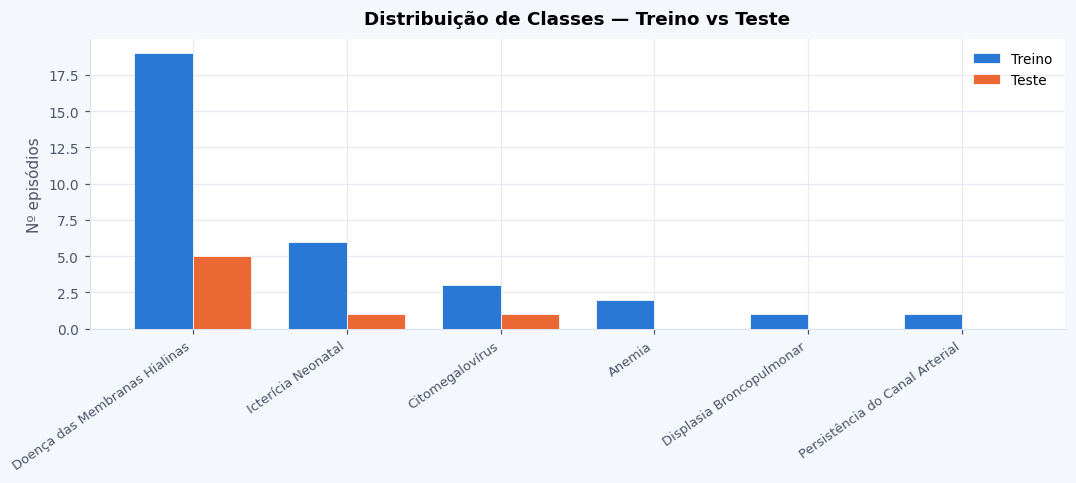

In [3]:
features_com_pat = [r for r in features if r["pat_label"] >= 0]

por_classe = defaultdict(list)
for row in features_com_pat:
    por_classe[row["pat_label"]].append(row)

train_rows, test_rows = [], []
for lbl, rows in sorted(por_classe.items()):
    shuffled = rows[:]
    random.shuffle(shuffled)
    n_train = max(1, round(len(shuffled) * 0.8))
    train_rows.extend(shuffled[:n_train])
    test_rows.extend(shuffled[n_train:])

print(f"Episódios com patologia: {len(features_com_pat)}")
print(f"Treino: {len(train_rows)}  |  Teste: {len(test_rows)}")
print()

train_dist = Counter(r["pat_predominante"] for r in train_rows)
test_dist  = Counter(r["pat_predominante"] for r in test_rows)

print(f"{'Patologia':<36}  {'Treino':>6}  {'Teste':>6}  {'% treino':>8}")
print("-" * 62)
for p in pats_por_freq:
    tr  = train_dist.get(p, 0)
    te  = test_dist.get(p, 0)
    tot = tr + te
    pct = tr / tot * 100 if tot else 0
    print(f"  {p:<34}  {tr:>6}  {te:>6}  {pct:>7.1f}%")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(pats_por_freq))
w = 0.38
ax.bar(x - w/2, [train_dist.get(p,0) for p in pats_por_freq],
       width=w, label="Treino", color=C["blue"], zorder=3,
       edgecolor=C["surf"], linewidth=0.5)
ax.bar(x + w/2, [test_dist.get(p,0)  for p in pats_por_freq],
       width=w, label="Teste",  color=C["orange"], zorder=3,
       edgecolor=C["surf"], linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(pats_por_freq, rotation=35, ha="right", fontsize=8.5)
ax.set_title("Distribuição de Classes — Treino vs Teste",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Nº episódios")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

## 3. Normalização Z-score

Os parâmetros (média, DP) são calculados **exclusivamente no conjunto de treino**
para evitar data leakage. O mesmo escalonamento é aplicado ao teste.

In [4]:
def z_score_params(rows, cols):
    params = {}
    for c in cols:
        vals = [r[c] for r in rows if r[c] is not None]
        mu   = statistics.mean(vals)
        sd   = statistics.stdev(vals) if len(vals) > 1 else 1.0
        params[c] = (mu, max(sd, 1e-9))
    return params

def apply_z_score(rows, params):
    for row in rows:
        for c, (mu, sd) in params.items():
            v = row.get(c)
            row[c + "_z"] = round((v - mu) / sd, 6) if v is not None else 0.0

params_train = z_score_params(train_rows, FEATURE_COLS)
apply_z_score(train_rows, params_train)
apply_z_score(test_rows,  params_train)

print("Normalização Z-score aplicada (parâmetros do treino).")
print(f"  {'Feature':<28}  {'Média':>8}  {'DP':>8}")
print("-" * 50)
for c, (mu, sd) in params_train.items():
    print(f"  {c:<28}  {mu:>8.3f}  {sd:>8.3f}")

Normalização Z-score aplicada (parâmetros do treino).
  Feature                          Média        DP
--------------------------------------------------
  sat_o2_mean                     96.218     1.327
  sat_o2_std                       1.693     0.481
  sat_o2_min                      90.775     3.324
  sat_o2_max                      99.406     0.678
  puls_rate_mean                 142.469    10.428
  puls_rate_std                    9.800     2.932
  puls_rate_min                  117.917    11.331
  puls_rate_max                  166.336    13.170
  perfusion_mean                   1.179     0.198
  perfusion_std                    0.396     0.127
  perfusion_min                    0.550     0.182
  perfusion_max                    2.690     0.809
  desat_count                      3.312    11.953
  desat_pct                        0.725     1.724


## 4. Guardar ficheiros de treino/teste

| Ficheiro | Conteúdo |
|---|---|
| `train.csv` | Conjunto de treino com features normalizadas (`_z`) |
| `test.csv` | Conjunto de teste com mesma normalização |
| `normalisation_params.csv` | Parâmetros z-score calculados no treino |

In [5]:
def write_csv(path, rows, fieldnames):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)
    print(f"  {Path(path).name:<32}  {len(rows):>4} linhas")

BASE_COLS   = ["episodio", "n_registos"]
TARGET_COLS = ["duracao_dias", "carga_dessaturacao", "pat_predominante", "pat_label"]
Z_COLS      = [c + "_z" for c in FEATURE_COLS]

print("Ficheiros criados (Fase 4):")
write_csv(OUT_DIR / "train.csv",
          train_rows,
          BASE_COLS + FEATURE_COLS + Z_COLS + TARGET_COLS)

write_csv(OUT_DIR / "test.csv",
          test_rows,
          BASE_COLS + FEATURE_COLS + Z_COLS + TARGET_COLS)

write_csv(OUT_DIR / "normalisation_params.csv",
          [{"feature": c, "mean": round(mu, 6), "std": round(sd, 6)}
           for c, (mu, sd) in params_train.items()],
          ["feature", "mean", "std"])

Ficheiros criados (Fase 4):
  train.csv                           32 linhas
  test.csv                             7 linhas
  normalisation_params.csv            14 linhas


## 5. Distribuição de classes — treino vs teste

Verificação visual da estratificação.

Episódios com patologia: 39
Treino: 32  |  Teste: 7

Patologia                             Treino   Teste  % treino
--------------------------------------------------------------
  Doença das Membranas Hialinas           19       5     79.2%
  Icterícia Neonatal                       6       1     85.7%
  Citomegalovírus                          3       1     75.0%
  Anemia                                   2       0    100.0%
  Displasia Broncopulmonar                 1       0    100.0%
  Persistência do Canal Arterial           1       0    100.0%


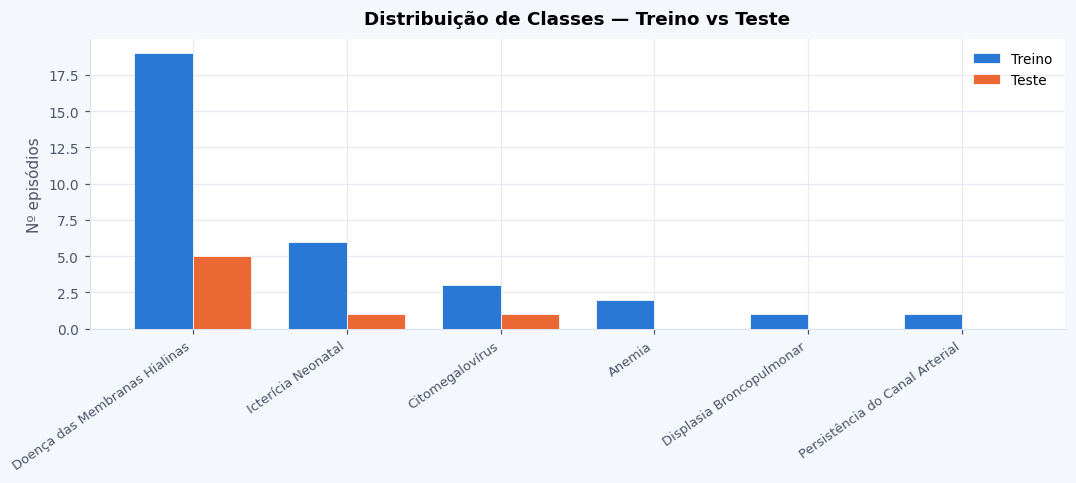

In [6]:
train_dist = Counter(r["pat_predominante"] for r in train_rows)
test_dist  = Counter(r["pat_predominante"] for r in test_rows)

print(f"Episódios com patologia: {len(features_com_pat)}")
print(f"Treino: {len(train_rows)}  |  Teste: {len(test_rows)}")
print()
print(f"{'Patologia':<36}  {'Treino':>6}  {'Teste':>6}  {'% treino':>8}")
print("-" * 62)
for p in pats_por_freq:
    tr  = train_dist.get(p, 0)
    te  = test_dist.get(p, 0)
    tot = tr + te
    pct = tr / tot * 100 if tot else 0
    print(f"  {p:<34}  {tr:>6}  {te:>6}  {pct:>7.1f}%")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(pats_por_freq))
w = 0.38
ax.bar(x - w/2, [train_dist.get(p,0) for p in pats_por_freq],
       width=w, label="Treino", color=C["blue"], zorder=3,
       edgecolor=C["surf"], linewidth=0.5)
ax.bar(x + w/2, [test_dist.get(p,0)  for p in pats_por_freq],
       width=w, label="Teste",  color=C["orange"], zorder=3,
       edgecolor=C["surf"], linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(pats_por_freq, rotation=35, ha="right", fontsize=8.5)
ax.set_title("Distribuição de Classes — Treino vs Teste",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Nº episódios")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

## 6. Modelos de classificação

*(Secção a preencher — implementar classificadores: k-NN, Naive Bayes, Árvore de Decisão)*

Estrutura sugerida para cada modelo:
1. Treinar com `X_train_z` e `y_train`
2. Prever `y_pred` sobre `X_test_z`
3. Calcular: acurácia, F1-macro, matriz de confusão
4. Comparar modelos numa tabela resumo

In [7]:
# Preparar arrays X/y para os modelos
X_train = [[r[c] for c in FEATURE_COLS]    for r in train_rows]
y_train = [int(r["pat_label"])              for r in train_rows]
X_test  = [[r[c] for c in FEATURE_COLS]    for r in test_rows]
y_test  = [int(r["pat_label"])              for r in test_rows]
X_train_z = [[r[c + "_z"] for c in FEATURE_COLS] for r in train_rows]
X_test_z  = [[r[c + "_z"] for c in FEATURE_COLS] for r in test_rows]

print(f"X_train: {len(X_train)} x {len(X_train[0])}")
print(f"X_test:  {len(X_test)} x {len(X_test[0])}")
print(f"Classes no treino: {sorted(set(y_train))}")
print(f"Classes no teste:  {sorted(set(y_test))}")
print()
print("→ Adicionar células seguintes com os classificadores.")

X_train: 32 x 14
X_test:  7 x 14
Classes no treino: [0, 1, 2, 3, 4, 5]
Classes no teste:  [0, 1, 2]

→ Adicionar células seguintes com os classificadores.
